# Analisis Dataset Kopi: Data Loading sampai Evaluasi Model

Notebook ini memuat:
1. Data loading
2. Data cleaning
3. EDA/EXDA (Exploratory Data Analysis)
4. Pembagian data train-test
5. Modeling regresi
6. Evaluasi dengan MAE, MSE, dan R²

Dataset utama: `merged_data_cleaned.csv` di dalam `archive.zip`. Target prediksi: `Total.Cup.Points`.

**Catatan metodologi:** kolom komponen penilaian cupping seperti `Aroma`, `Flavor`, dan `Cupper.Points` dikeluarkan dari fitur karena berhubungan langsung dengan skor total dan dapat menyebabkan *target leakage*. 

In [1]:
# 1. Import library
import os
import zipfile
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)


## 2. Data loading

In [2]:
# Data loading yang lebih aman: cari file di folder kerja, lalu tampilkan file picker jika belum ditemukan.
import os
import zipfile
import pandas as pd

zip_candidates = [
    os.path.abspath("archive.zip"),
    os.path.join(os.getcwd(), "archive.zip"),
    r"C:\Users\Public\Downloads\archive.zip"
]
csv_candidates = [
    os.path.abspath("merged_data_cleaned.csv"),
    os.path.join(os.getcwd(), "merged_data_cleaned.csv")
]
zip_path = next((p for p in dict.fromkeys(zip_candidates) if os.path.isfile(p)), None)
csv_path = next((p for p in dict.fromkeys(csv_candidates) if os.path.isfile(p)), None)

# Jika file belum ditemukan, coba buka jendela untuk memilih file secara manual.
if zip_path is None and csv_path is None:
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        selected = filedialog.askopenfilename(
            title="Pilih archive.zip atau merged_data_cleaned.csv",
            filetypes=[("Dataset ZIP/CSV", "*.zip *.csv"), ("Semua file", "*.*")]
        )
        root.destroy()
        if selected and selected.lower().endswith(".zip"):
            zip_path = selected
        elif selected and selected.lower().endswith(".csv"):
            csv_path = selected
    except Exception:
        pass

if zip_path:
    with zipfile.ZipFile(zip_path, "r") as zf:
        csv_inside = next((n for n in zf.namelist() if os.path.basename(n) == "merged_data_cleaned.csv"), None)
        if csv_inside is None:
            raise FileNotFoundError("merged_data_cleaned.csv tidak ditemukan di dalam ZIP. Isi ZIP: " + str(zf.namelist()))
        with zf.open(csv_inside) as f:
            df = pd.read_csv(f)
elif csv_path:
    df = pd.read_csv(csv_path)
else:
    raise FileNotFoundError(
        "Dataset belum ditemukan. Taruh archive.zip di folder yang sama dengan notebook, "
        "atau pilih file saat jendela pemilihan muncul. Folder kerja saat ini: " + os.getcwd()
    )

print("File sumber:", zip_path or csv_path)
print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head())
print("\nTipe data dan non-null:")
df.info()


Ukuran dataset (baris, kolom): (1339, 44)


,Unnamed: 0,Species,Owner,Country.of.Origin,Farm.Name,Lot.Number,Mill,ICO.Number,Company,Altitude,Region,Producer,Number.of.Bags,Bag.Weight,In.Country.Partner,Harvest.Year,Grading.Date,Owner.1,Variety,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Cupper.Points,Total.Cup.Points,Moisture,Category.One.Defects,Quakers,Color,Category.Two.Defects,Expiration,Certification.Body,Certification.Address,Certification.Contact,unit_of_measurement,altitude_low_meters,altitude_high_meters,altitude_mean_meters
0,0,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,NaN,Washed / Wet,8.67,8.83,8.67,8.75,8.50,8.42,10.0,10.0,10.0,8.75,90.58,0.12,0,0.0,Green,0,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
1,1,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,Other,Washed / Wet,8.75,8.67,8.50,8.58,8.42,8.42,10.0,10.0,10.0,8.58,89.92,0.12,0,0.0,Green,1,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
2,2,Arabica,grounds for health admin,Guatemala,"san marcos barrancas ""san cristobal cuch",NaN,NaN,NaN,NaN,1600 - 1800 m,NaN,NaN,5,1,Specialty Coffee Association,NaN,"May 31st, 2010",Grounds for Health Admin,Bourbon,NaN,8.42,8.50,8.42,8.42,8.33,8.42,10.0,10.0,10.0,9.25,89.75,0.00,0,0.0,NaN,0,"May 31st, 2011",Specialty Coffee Association,36d0d00a3724338ba7937c52a378d085f2172daa,0878a7d4b9d35ddbf0fe2ce69a2062cceb45a660,m,1600.0,1800.0,1700.0
3,3,Arabica,yidnekachew dabessa,Ethiopia,yidnekachew dabessa coffee plantation,NaN,wolensu,NaN,yidnekachew debessa coffee plantation,1800-2200,oromia,Yidnekachew Dabessa Coffee Plantation,320,60 kg,METAD Agricultural Development plc,2014,"March 26th, 2015",Yidnekachew Dabessa,NaN,Natural / Dry,8.17,8.58,8.42,8.42,8.50,8.25,10.0,10.0,10.0,8.67,89.00,0.11,0,0.0,Green,2,"March 25th, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1800.0,2200.0,2000.0
4,4,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,Other,Washed / Wet,8.25,8.50,8.25,8.50,8.42,8.33,10.0,10.0,10.0,8.58,88.83,0.12,0,0.0,Green,2,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0



Tipe data dan non-null:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1339 entries, 0 to 1338
Data columns (total 44 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             1339 non-null   int64  
 1   Species                1339 non-null   object 
 2   Owner                  1332 non-null   object 
 3   Country.of.Origin      1338 non-null   object 
 4   Farm.Name              980 non-null    object 
 5   Lot.Number             276 non-null    object 
 6   Mill                   1021 non-null   object 
 7   ICO.Number             1180 non-null   object 
 8   Company                1130 non-null   object 
 9   Altitude               1113 non-null   object 
 10  Region                 1280 non-null   object 
 11  Producer               1107 non-null   object 
 12  Number.of.Bags         1339 non-null   int64  
 13  Bag.Weight             1339 non-null   object 
 14  In.Country.Partner     1339 non

## 3. Data cleaning

In [3]:
df = df.copy()

# Hapus kolom indeks otomatis, jika ada
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("unnamed:")],
             errors="ignore")

# Standarkan nilai kosong yang tertulis sebagai teks
df = df.replace(["", " ", "NA", "N/A", "null", "None", "nan"], np.nan)

duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

target = "Total.Cup.Points"
if target not in df.columns:
    raise KeyError(f"Kolom target '{target}' tidak ditemukan.")

df[target] = pd.to_numeric(df[target], errors="coerce")
missing_target_before = int(df[target].isna().sum())
df = df.dropna(subset=[target]).copy()

# Konversi kolom numerik yang mungkin tersimpan sebagai teks
for col in [
    "Number.of.Bags", "Moisture", "Quakers", "Category.One.Defects",
    "Category.Two.Defects", "altitude_low_meters", "altitude_high_meters",
    "altitude_mean_meters", "Harvest.Year"
]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Duplikat dihapus:", duplicates_before)
print("Baris dengan target kosong dihapus:", missing_target_before)
print("Ukuran setelah cleaning:", df.shape)
print("\nMissing value terbanyak:")
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("jumlah_missing"))
print("\nStatistik deskriptif:")
display(df.describe(include="all").T)


Duplikat dihapus: 0
Baris dengan target kosong dihapus: 0
Ukuran setelah cleaning: (1339, 43)

Missing value terbanyak:


,jumlah_missing
Lot.Number,1063
Farm.Name,359
Mill,318
Color,270
Producer,232
altitude_high_meters,230
altitude_low_meters,230
altitude_mean_meters,230
Altitude,226
Variety,226



Statistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Species,1339,2,Arabica,1311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,1332,315,juan luis alvarado romero,155,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country.of.Origin,1338,36,Mexico,236,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Farm.Name,980,571,various,47,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Lot.Number,276,227,1,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mill,1021,459,beneficio ixchel,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ICO.Number,1180,846,0,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Company,1130,281,"unex guatemala, s.a.",86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Altitude,1113,396,1100,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,1280,356,huila,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. EDA / EXDA (Exploratory Data Analysis)

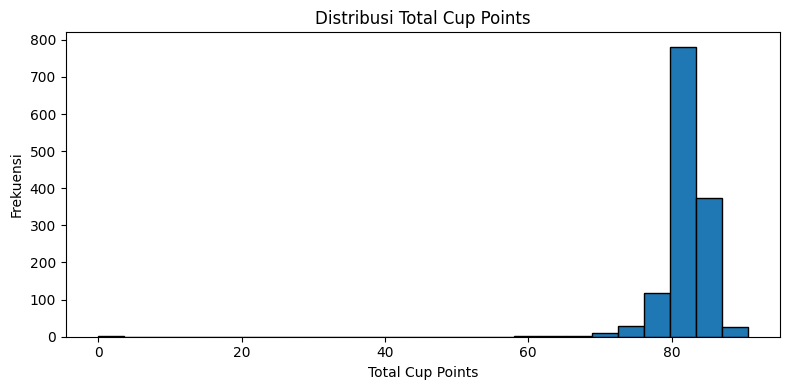

,Total.Cup.Points
count,1339.000000
mean,82.089851
std,3.500575
min,0.000000
25%,81.080000
50%,82.500000
75%,83.670000
max,90.580000


In [4]:
# Distribusi target kualitas kopi
plt.figure(figsize=(8, 4))
plt.hist(df[target].dropna(), bins=25, edgecolor="black")
plt.title("Distribusi Total Cup Points")
plt.xlabel("Total Cup Points")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

display(df[target].describe().to_frame("Total.Cup.Points"))


Jumlah data per spesies:


,jumlah
Species,
Arabica,1311
Robusta,28


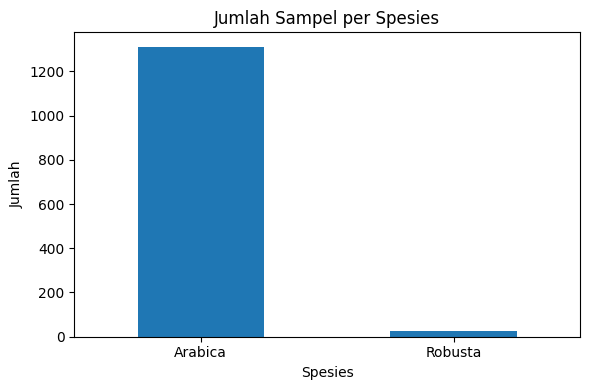

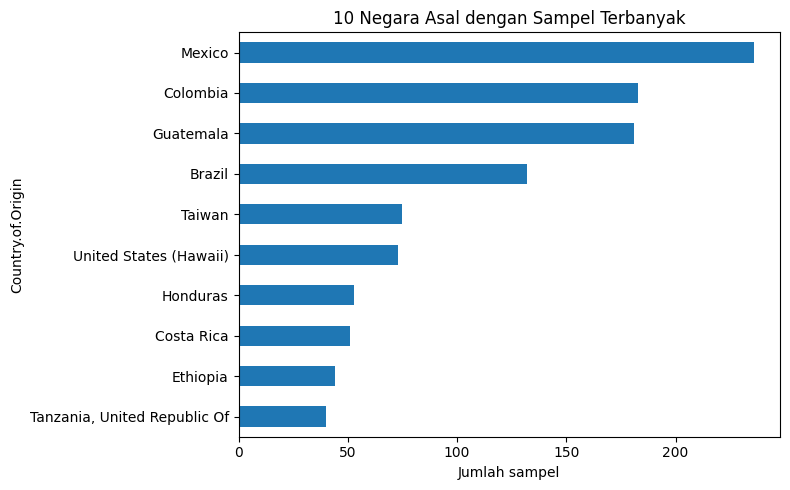

In [5]:
# Komposisi spesies kopi
if "Species" in df.columns:
    print("Jumlah data per spesies:")
    display(df["Species"].value_counts(dropna=False).to_frame("jumlah"))
    df["Species"].value_counts().plot(kind="bar", figsize=(6, 4), rot=0,
                                      title="Jumlah Sampel per Spesies")
    plt.xlabel("Spesies")
    plt.ylabel("Jumlah")
    plt.tight_layout()
    plt.show()

# 10 negara asal dengan sampel terbanyak
if "Country.of.Origin" in df.columns:
    top_countries = df["Country.of.Origin"].value_counts().head(10)
    top_countries.sort_values().plot(kind="barh", figsize=(8, 5),
                                     title="10 Negara Asal dengan Sampel Terbanyak")
    plt.xlabel("Jumlah sampel")
    plt.tight_layout()
    plt.show()


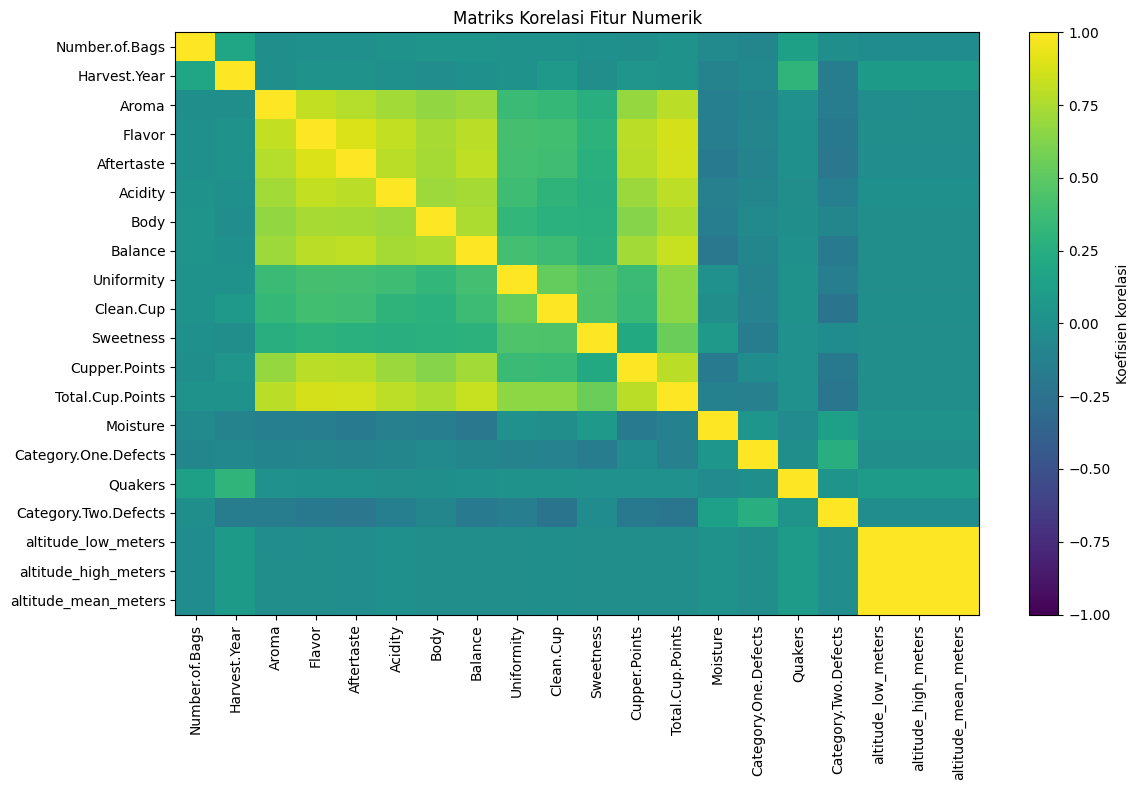

,korelasi_dengan_target
Total.Cup.Points,1.000000
Flavor,0.874279
Aftertaste,0.860656
Balance,0.828502
Acidity,0.797024
Aroma,0.791627
Cupper.Points,0.790217
Body,0.757165
Clean.Cup,0.658859
Uniformity,0.656454


In [6]:
# Korelasi fitur numerik dengan target
numeric_eda = df.select_dtypes(include=np.number)
if numeric_eda.shape[1] >= 2:
    corr = numeric_eda.corr(numeric_only=True)
    plt.figure(figsize=(12, 8))
    plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    plt.colorbar(label="Koefisien korelasi")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.title("Matriks Korelasi Fitur Numerik")
    plt.tight_layout()
    plt.show()
    display(corr[target].sort_values(ascending=False).to_frame("korelasi_dengan_target"))


## 5. Menentukan fitur dan target

Target adalah `Total.Cup.Points`. Kolom skor komponen cupping dihapus dari fitur agar model tidak menggunakan bagian-bagian yang secara langsung membentuk skor target. Kolom identitas dan kontak juga tidak digunakan sebagai prediktor.

In [7]:
target = "Total.Cup.Points"

leakage_cols = [
    "Aroma", "Fragrance...Aroma", "Flavor", "Aftertaste", "Acidity",
    "Salt...Acid", "Body", "Balance", "Bitter...Sweet", "Mouthfeel",
    "Uniformity", "Uniform.Cup", "Clean.Cup", "Sweetness", "Cupper.Points"
]
id_text_cols = [
    "Owner", "Owner.1", "Farm.Name", "Lot.Number", "Mill", "ICO.Number",
    "Company", "Producer", "In.Country.Partner", "Grading.Date", "Expiration",
    "Certification.Body", "Certification.Address", "Certification.Contact",
    "Altitude", "Bag.Weight", "Region"
]

drop_cols = [c for c in [target] + leakage_cols + id_text_cols if c in df.columns]
X = df.drop(columns=drop_cols, errors="ignore").copy()
y = df[target].copy()

X = X.dropna(axis=1, how="all")
constant_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=constant_cols, errors="ignore")

# Hapus kategori ber-cardinality sangat tinggi untuk mencegah fitur yang terlalu jarang
high_cardinality_cols = [
    c for c in X.select_dtypes(exclude=np.number).columns
    if X[c].nunique(dropna=True) > 50
]
X = X.drop(columns=high_cardinality_cols, errors="ignore")

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Jumlah sampel:", len(X))
print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)
print("Kolom target:", target)


Jumlah sampel: 1339
Fitur numerik: ['Number.of.Bags', 'Harvest.Year', 'Moisture', 'Category.One.Defects', 'Quakers', 'Category.Two.Defects', 'altitude_low_meters', 'altitude_high_meters', 'altitude_mean_meters']
Fitur kategorikal: ['Species', 'Country.of.Origin', 'Variety', 'Processing.Method', 'Color', 'unit_of_measurement']
Kolom target: Total.Cup.Points


## 6. Pembagian dataset menjadi train dan test

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Total data : {len(X)}")
print(f"Data train: {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Data test : {len(X_test)} ({len(X_test)/len(X):.0%})")


Total data : 1339
Data train: 1071 (80%)
Data test : 268 (20%)


## 7. Modeling

In [9]:
# Semua preprocessing dipasang di Pipeline agar imputer/encoder/scaler
# dipelajari hanya dari data train, bukan dari data test.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=RANDOM_STATE,
        min_samples_leaf=2, n_jobs=-1
    )
}

results = []
fitted_models = {}
predictions_by_model = {}

for name, estimator in models.items():
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted_models[name] = model
    predictions_by_model[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(results_df)


,Model,MAE,MSE,R2
0,Random Forest,2.004791,31.245564,0.018971
1,Linear Regression,2.089522,31.034841,0.025587


## 8. Evaluasi MAE, MSE, dan R²

Model terbaik berdasarkan MAE: Random Forest
MAE = 2.0048
MSE = 31.2456
R²  = 0.0190


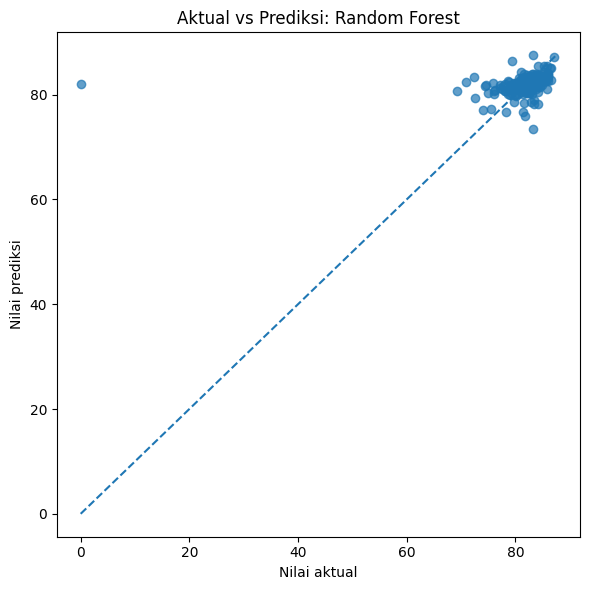

In [10]:
best_name = results_df.loc[0, "Model"]
best_pred = predictions_by_model[best_name]

print("Model terbaik berdasarkan MAE:", best_name)
print(f"MAE = {mean_absolute_error(y_test, best_pred):.4f}")
print(f"MSE = {mean_squared_error(y_test, best_pred):.4f}")
print(f"R²  = {r2_score(y_test, best_pred):.4f}")

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.7)
low = min(float(y_test.min()), float(np.min(best_pred)))
high = max(float(y_test.max()), float(np.max(best_pred)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Nilai aktual")
plt.ylabel("Nilai prediksi")
plt.title(f"Aktual vs Prediksi: {best_name}")
plt.tight_layout()
plt.show()


## 9. Kesimpulan dan arti metrik

- **MAE (Mean Absolute Error):** rata-rata selisih absolut prediksi dan nilai aktual; makin kecil makin baik.
- **MSE (Mean Squared Error):** rata-rata kuadrat kesalahan; makin kecil makin baik dan kesalahan besar mendapat penalti lebih tinggi.
- **R²:** mengukur proporsi variasi target yang dapat dijelaskan model. Nilai mendekati 1 umumnya baik; nilai negatif berarti lebih buruk daripada prediksi sederhana menggunakan rata-rata target.

Bandingkan MAE, MSE, dan R² pada tabel. Nilai evaluasi berasal dari data test yang tidak digunakan saat fitting. Hasil dapat terbatas karena fitur skor cupping langsung sengaja dikeluarkan untuk mencegah kebocoran target.